# Pobreza monetaria e informalidad laboral en el Perú — **Hito 2**
### Preparación de datos y primera matriz analítica
**Integración de la ENAHO 2024 (Módulo 500 — Empleo e Ingresos) con el Mapa de Pobreza Monetaria Distrital 2018 (INEI)**

Integrantes: Thiago Ormeño y Daniela Eléspuru

---

Este cuaderno es **completamente reproducible**: parte de los dos archivos originales del INEI y
termina en la matriz analítica. Reemplaza al cuaderno del Hito 1 en todo lo relativo a la construcción
de la variable de informalidad, por las razones que se explican en la sección 0.

| Sección | Contenido |
|---|---|
| 0 | Correcciones y precisiones respecto del Hito 1 |
| 1 | Carga e inspección de las dos fuentes |
| 2 | Diagnóstico de calidad (antes de tocar nada) |
| 3 | Tratamiento de calidad y construcción de la informalidad |
| 4 | Granularidad: de persona a distrito |
| 5 | Integración validada (claves, cardinalidad, emparejados / no emparejados) |
| 6 | EDA sobre la base integrada |
| 7 | Transformación de variables |
| 8 | Matriz analítica |
| 9 | Próximo paso |

## 0. Correcciones y precisiones respecto del Hito 1


**0.1 `CODINFOR` no es la condición de informalidad.** En el Hito 1 se definió
`ES_INFORMAL = (CODINFOR == 1)`. Al revisar la variable contra los microdatos, `CODINFOR` toma
**16 valores distintos (0 a 16)** y está ubicada en el bloque de identificación del registro, junto a
`CONGLOME`, `VIVIENDA`, `HOGAR` y `CODPERSO`: es el **código del informante**, es decir, qué miembro del
hogar respondió la encuesta. La tasa que reportaba el Hito 1 (≈ 47.8 % nacional) era en realidad el
porcentaje de trabajadores cuya entrevista fue respondida por la persona número 1 del hogar. La
sección 3 reconstruye la informalidad con la definición operativa del INEI y valida el resultado
contra la cifra oficial publicada.

**0.2 El resultado central del Hito 1 se invierte.** Con la variable corregida, la correlación
distrital entre informalidad y pobreza deja de ser nula y pasa a ser **positiva y moderada**. La
conclusión del Hito 1 ("informalidad y pobreza son fenómenos independientes") era un artefacto de la
variable mal construida. El objetivo de análisis se reformula en consecuencia (sección 6).

**0.3 La limpieza del anexo de pobreza y del cruce se rehízo.** El Hito 1 recortaba el anexo con
`iloc[6:]` y luego eliminaba filas con `dropna(thresh=...)`, lo que **borraba silenciosamente** los
distritos sin pareja en vez de documentarlos. Ahora las filas de cabecera y los separadores
"Continúa…" se filtran por patrón de UBIGEO, y los registros no emparejados se cuantifican y se
analizan explícitamente (sección 5).

**0.4 Precisiones menores.** El ingreso se reexpresa en soles **mensuales** (la variable `I524A1` está
en soles anuales y en el Hito 1 quedó rotulada de forma ambigua); `UBICACION_POBREZA_MONETARIA_TOTAL`
se trata como **ranking** y no como tasa, y la tasa de pobreza se reconstruye como punto medio del
intervalo de confianza publicado; y el UBIGEO se conserva como texto de 6 dígitos **también al
exportar** (en el Hito 1 se guardaba como entero y perdía el cero inicial).

In [ ]:
# ============================================================
# Librerías y configuración
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from pathlib import Path

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

# ---- Rutas (ajustar si se ejecuta en Colab) ----
RUTA_ENAHO  = "DB/2024Empleo e Ingresos.csv"
RUTA_INEI   = "DB/Anexo Estadístico.xlsx"
CARPETA_OUT = Path("output"); CARPETA_OUT.mkdir(exist_ok=True)
CARPETA_FIG = CARPETA_OUT / "figuras"; CARPETA_FIG.mkdir(exist_ok=True)

SEMILLA = 42
np.random.seed(SEMILLA)
print("Entorno listo · pandas", pd.__version__)

Entorno listo · pandas 2.3.3


## 1. Carga e inspección de las fuentes

### 1.1 Fuente 1 — ENAHO 2024, Módulo 500 (Empleo e Ingresos)

El archivo original tiene **1 425 columnas**. Se cargan solo las 26 necesarias con `usecols`, lo que
reduce el consumo de memoria de varios GB a unas decenas de MB. Cada fila es **una persona**.

Respecto del Hito 1 se incorporan tres variables nuevas, indispensables para construir la
informalidad con la definición del INEI: `P510B` (registro del negocio como persona jurídica),
`P558A5` (no afiliación a ningún sistema de pensiones) y `P510A1` (registro contable). Se retiran
`D524A1` (redundante con `I524A1`) y `P558T` (monto de pensión, no afiliación).

In [ ]:
# Columnas relevantes de la ENAHO 2024 (de 1,425 disponibles)
COLUMNAS_ENAHO = [
    # --- Identificación y geografía ---
    "AÑO", "MES", "UBIGEO", "DOMINIO", "ESTRATO",
    "CONGLOME", "VIVIENDA", "HOGAR", "CODPERSO",
    "CODINFOR",   # OJO: código del INFORMANTE, no informalidad (ver sección 0.1 y 2.3)
    # --- Perfil del trabajador ---
    "P207",   # Sexo
    "P208A",  # Edad
    "P301A",  # Nivel educativo alcanzado
    # --- Ocupación y sector ---
    "P506R4", # Actividad económica del empleador (CIIU rev.4)
    "P507",   # Categoría ocupacional
    # --- Insumos de la informalidad (definición INEI) ---
    "P510A1", # Registro contable del negocio
    "P510B",  # Negocio registrado como persona jurídica
    "P511A",  # Tipo de contrato
    "P512A",  # Tamaño de la empresa
    "P558A5", # Marca "no afiliado a ningún sistema de pensiones"
    # --- Horas, subempleo e ingresos ---
    "I513T",  # Horas semanales en la ocupación principal (imputada)
    "P520",   # Horas normales semanales
    "P521",   # ¿Quería trabajar más horas?
    "I524A1", # Ingreso de la ocupación principal (imputado, soles ANUALES)
    # --- Condición de ocupación y ponderador ---
    "OCU500", # Condición de ocupación
    "FAC500A",# Factor de expansión muestral
]

RENOMBRAR = {
    "P207": "sexo", "P208A": "edad", "P301A": "nivel_educativo",
    "P506R4": "ciiu_actividad", "P507": "categoria_ocupacional",
    "P510A1": "registro_contable", "P510B": "registro_persona_juridica",
    "P511A": "tipo_contrato", "P512A": "tamano_empresa",
    "P558A5": "no_afiliado_pension",
    "I513T": "horas_semana", "P520": "horas_normales", "P521": "quiere_mas_horas",
    "I524A1": "ingreso_principal_anual",
    "OCU500": "condicion_ocupacion", "FAC500A": "factor_expansion",
}

enaho = (pd.read_csv(RUTA_ENAHO,
                     usecols=lambda c: c in COLUMNAS_ENAHO,
                     encoding="latin-1",        # los microdatos del INEI vienen en latin-1
                     low_memory=False)
           .rename(columns=RENOMBRAR))

print(f"ENAHO cargada · filas (personas): {enaho.shape[0]:,} · columnas: {enaho.shape[1]}")
enaho.head()

ENAHO cargada · filas (personas): 85,992 · columnas: 26


,AÑO,MES,CONGLOME,VIVIENDA,HOGAR,CODPERSO,UBIGEO,DOMINIO,ESTRATO,CODINFOR,ciiu_actividad,categoria_ocupacional,registro_contable,registro_persona_juridica,tipo_contrato,tamano_empresa,horas_normales,quiere_mas_horas,no_afiliado_pension,sexo,edad,nivel_educativo,horas_semana,ingreso_principal_anual,condicion_ocupacion,factor_expansion
0,2024,1,15009,13,11,1,10101,4,4,1,,,,,,,,,0,1,45,11,,,4,136.036972
1,2024,1,15009,13,11,2,10101,4,4,2,9000,2,3,2,,1,,2,5,2,19,9,35,,1,75.679695
2,2024,1,15009,47,11,1,10101,4,4,1,8010,3,1,1,1,4,,2,0,2,39,8,36,11267,1,68.032333
3,2024,1,15009,47,11,2,10101,4,4,2,4771,3,2,2,7,1,,2,5,2,19,9,36,6447,1,75.679695
4,2024,1,15009,59,11,1,10101,4,4,1,4922,2,3,2,,1,,2,5,1,57,5,54,,1,81.480087


In [ ]:
# Inspección inicial: tipos y estadísticos ANTES de cualquier limpieza
print("Tipos de dato detectados:")
display(enaho.dtypes.to_frame("dtype"))
print("Estadísticos descriptivos (columnas numéricas):")
display(enaho.describe().T.round(2))

Tipos de dato detectados:


,dtype
AÑO,int64
MES,int64
CONGLOME,int64
VIVIENDA,int64
HOGAR,int64
CODPERSO,int64
UBIGEO,int64
DOMINIO,int64
ESTRATO,int64
CODINFOR,int64


Estadísticos descriptivos (columnas numéricas):


,count,mean,std,min,25%,50%,75%,max
AÑO,85992.0,2024.00,0.00,2024.00,2024.00,2024.00,2024.00,2024.00
MES,85992.0,6.46,3.45,1.00,3.00,6.00,9.00,12.00
CONGLOME,85992.0,17775.08,1633.01,10651.00,16382.00,17741.00,19193.00,21001.00
VIVIENDA,85992.0,76.98,67.57,1.00,31.00,66.00,104.00,945.00
HOGAR,85992.0,11.12,1.24,11.00,11.00,11.00,11.00,55.00
CODPERSO,85992.0,2.14,1.34,1.00,1.00,2.00,3.00,16.00
UBIGEO,85992.0,130677.26,67324.58,10101.00,70107.00,140106.00,180301.00,250401.00
DOMINIO,85992.0,4.88,2.40,1.00,3.00,5.00,7.00,8.00
ESTRATO,85992.0,4.07,2.43,1.00,2.00,4.00,7.00,8.00
CODINFOR,85992.0,1.98,1.25,0.00,1.00,2.00,2.00,16.00


### 1.2 Fuente 2 — Mapa de Pobreza Monetaria Distrital 2018 (Anexo Estadístico)

El anexo es una tabla pensada para imprimirse, no para leerse con software: trae **7 filas de
cabecera** con el título y los encabezados en dos niveles, y **filas "Continúa…"** cada 47 registros,
donde se corta la página. El Hito 1 las eliminaba después del cruce con un `dropna` que también
borraba distritos legítimos. Aquí se filtran antes, por un criterio explícito: **se conserva solo lo
que tenga un UBIGEO de exactamente 6 dígitos**. Cada fila es **un distrito**.

In [ ]:
anexo_crudo = pd.read_excel(RUTA_INEI, header=None)
print("Anexo tal como viene:", anexo_crudo.shape)
display(anexo_crudo.head(9))

anexo_crudo.columns = ["UBIGEO", "DEPARTAMENTO", "PROVINCIA", "DISTRITO",
                       "POBLACION_2020", "IC_INFERIOR", "IC_SUPERIOR",
                       "GRUPOS_ROBUSTOS", "RANKING_POBREZA"]

# Regla de corte explícita: solo filas cuyo UBIGEO sea texto de exactamente 6 dígitos
es_distrito = anexo_crudo["UBIGEO"].astype(str).str.fullmatch(r"\d{6}")
print(f"\nFilas descartadas (cabeceras, 'Continúa…', pie de página): {(~es_distrito).sum()}")
display(anexo_crudo[~es_distrito].head(4))

pobreza = anexo_crudo[es_distrito].copy()
pobreza["UBIGEO"] = pobreza["UBIGEO"].astype(str).str.zfill(6)
for c in ["POBLACION_2020", "IC_INFERIOR", "IC_SUPERIOR", "GRUPOS_ROBUSTOS", "RANKING_POBREZA"]:
    pobreza[c] = pd.to_numeric(pobreza[c], errors="coerce")
for c in ["DEPARTAMENTO", "PROVINCIA", "DISTRITO"]:
    pobreza[c] = pobreza[c].astype(str).str.strip().str.title()

print(f"\nMapa de pobreza · distritos: {pobreza.shape[0]:,} · columnas: {pobreza.shape[1]}")
display(pobreza.describe(include="all").T)

Anexo tal como viene: (1922, 9)


/usr/local/lib/python3.10/dist-packages/openpyxl/reader/workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'A3.23'!$A:$I.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")


,0,1,2,3,4,5,6,7,8
0,Anexo N° 1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"PERÚ: POBREZA MONETARIA TOTAL, GRUPOS ROBUSTOS...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ubigeo,Departamento,Provincia,Distrito,Población proyectada\n2020\n1/,Intervalo de confianza al 95%,NaN,Grupos robustos 2/,Ubicación pobreza monetaria total \n3/
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,Inferior,Superior,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,050410,AYACUCHO,HUANTA,UCHURACCAY,3672,73.254961,89.268381,1,1
8,060308,CAJAMARCA,CELENDÍN,OXAMARCA,5824,74.592076,87.404338,1,2



Filas descartadas (cabeceras, 'Continúa…', pie de página): 49


,UBIGEO,DEPARTAMENTO,PROVINCIA,DISTRITO,POBLACION_2020,IC_INFERIOR,IC_SUPERIOR,GRUPOS_ROBUSTOS,RANKING_POBREZA
0,Anexo N° 1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"PERÚ: POBREZA MONETARIA TOTAL, GRUPOS ROBUSTOS...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Ubigeo,Departamento,Provincia,Distrito,Población proyectada\n2020\n1/,Intervalo de confianza al 95%,NaN,Grupos robustos 2/,Ubicación pobreza monetaria total \n3/



Mapa de pobreza · distritos: 1,873 · columnas: 9


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UBIGEO,1873,1873,150131,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DEPARTAMENTO,1873,25,Lima,170,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PROVINCIA,1873,196,Lima,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DISTRITO,1873,1727,Santa Rosa,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
POBLACION_2020,1873.0,NaN,NaN,NaN,17417.82221,56636.246418,137.0,1559.0,3963.0,10782.0,1177629.0
IC_INFERIOR,1873.0,NaN,NaN,NaN,24.460388,14.580347,0.0,13.275084,23.187937,33.805665,74.592076
IC_SUPERIOR,1873.0,NaN,NaN,NaN,43.841719,19.758502,0.114693,28.810419,44.780555,59.261748,90.477852
GRUPOS_ROBUSTOS,1873.0,NaN,NaN,NaN,11.459156,4.855339,1.0,8.0,11.0,15.0,28.0
RANKING_POBREZA,1873.0,NaN,NaN,NaN,937.187934,541.097329,1.0,469.0,937.0,1405.0,1874.0


## 2. Diagnóstico de calidad

Primero se **detecta**, sin corregir nada. El objetivo es dejar por escrito qué problema existe,
de qué tamaño es y sobre qué columnas cae, para que cada tratamiento de la sección 3 tenga una
justificación verificable y no sea una receta aplicada a ciegas.

In [ ]:
# UBIGEO como texto de 6 dígitos: al leerse como número pierde el cero inicial
# (Amazonas = '01...' se convertiría en 1...). Es la clave del cruce, así que se arregla primero.
enaho["UBIGEO"] = enaho["UBIGEO"].astype(str).str.zfill(6)

NUMERICAS = ["edad", "ingreso_principal_anual", "horas_semana", "horas_normales",
             "quiere_mas_horas", "factor_expansion", "nivel_educativo", "tamano_empresa",
             "ESTRATO", "CODINFOR", "condicion_ocupacion", "sexo", "categoria_ocupacional",
             "registro_persona_juridica", "registro_contable", "no_afiliado_pension", "DOMINIO"]
for c in NUMERICAS:
    enaho[c] = pd.to_numeric(enaho[c], errors="coerce")

LLAVE_PERSONA = ["CONGLOME", "VIVIENDA", "HOGAR", "CODPERSO"]

diagnostico = pd.DataFrame([
    ("ENAHO", "Filas duplicadas exactas", int(enaho.duplicated().sum())),
    ("ENAHO", "Personas duplicadas por llave CONGLOME+VIVIENDA+HOGAR+CODPERSO",
     int(enaho.duplicated(subset=LLAVE_PERSONA).sum())),
    ("ENAHO", "Edades fuera del rango [0, 100]",
     int(((enaho.edad < 0) | (enaho.edad > 100)).sum())),
    ("ENAHO", "Horas semanales fuera del rango [0, 168]",
     int(((enaho.horas_semana < 0) | (enaho.horas_semana > 168)).sum())),
    ("ENAHO", "Ingresos negativos", int((enaho.ingreso_principal_anual < 0).sum())),
    ("ENAHO", "Registros sin factor de expansión", int(enaho.factor_expansion.isna().sum())),
    ("ENAHO", "UBIGEO distintos presentes en la muestra", int(enaho.UBIGEO.nunique())),
    ("Pobreza", "Filas duplicadas exactas", int(pobreza.duplicated().sum())),
    ("Pobreza", "UBIGEO duplicados", int(pobreza.duplicated(subset=["UBIGEO"]).sum())),
    ("Pobreza", "Tasas fuera del rango [0, 100]",
     int(((pobreza.IC_INFERIOR < 0) | (pobreza.IC_SUPERIOR > 100)).sum())),
    ("Pobreza", "Distritos en el mapa (universo nacional)", int(len(pobreza))),
], columns=["Fuente", "Verificación", "Casos"])
display(diagnostico)

print("Porcentaje de valores faltantes por columna (ENAHO):")
display((enaho.isna().mean() * 100).round(2).sort_values(ascending=False).to_frame("% faltante").head(12))

,Fuente,Verificación,Casos
0,ENAHO,Filas duplicadas exactas,0
1,ENAHO,Personas duplicadas por llave CONGLOME+VIVIEND...,0
2,ENAHO,"Edades fuera del rango [0, 100]",0
3,ENAHO,"Horas semanales fuera del rango [0, 168]",0
4,ENAHO,Ingresos negativos,0
5,ENAHO,Registros sin factor de expansión,0
6,ENAHO,UBIGEO distintos presentes en la muestra,1271
7,Pobreza,Filas duplicadas exactas,0
8,Pobreza,UBIGEO duplicados,0
9,Pobreza,"Tasas fuera del rango [0, 100]",0


Porcentaje de valores faltantes por columna (ENAHO):


,% faltante
horas_normales,93.27
ingreso_principal_anual,70.54
registro_persona_juridica,34.32
registro_contable,34.32
tamano_empresa,27.14
quiere_mas_horas,26.88
categoria_ocupacional,26.88
horas_semana,26.88
no_afiliado_pension,0.24
nivel_educativo,0.09


### 2.1 Lectura del diagnóstico

La ENAHO llega **sin duplicados, sin valores imposibles y sin faltantes en el ponderador**: el INEI ya
entrega los microdatos consistentes. Esto es un resultado del diagnóstico, no un descuido — el Hito 1
describía estos tratamientos como si hubieran corregido algo, cuando en realidad el conteo es cero en
todos los casos. Los faltantes que sí existen se concentran en variables de ingreso y horas y
corresponden a **no aplicabilidad** (a un trabajador familiar no remunerado no se le pregunta el
ingreso), no a error de registro; por eso no se imputan a nivel de persona.

Los dos problemas reales están en otro lado: **la estructura del anexo de pobreza** (resuelta en 1.2)
y **la variable que se creyó que medía informalidad**.

### 2.2 Inconsistencia crítica: `CODINFOR` no mide informalidad

Si `CODINFOR` fuera la condición de informalidad, debería tener dos categorías. La celda siguiente
muestra que no es así.

In [ ]:
print("Distribución de CODINFOR (la variable que el Hito 1 usó como informalidad):")
display(enaho["CODINFOR"].value_counts().sort_index().to_frame("personas"))
print(f"→ CODINFOR toma {enaho['CODINFOR'].nunique()} valores distintos, "
      f"de {int(enaho['CODINFOR'].min())} a {int(enaho['CODINFOR'].max())}.")

# Evidencia adicional: su valor máximo por hogar crece con el tamaño del hogar,
# exactamente como lo haría un código de persona dentro del hogar.
tam_hogar = enaho.groupby(["CONGLOME", "VIVIENDA", "HOGAR"]).agg(
    personas_en_hogar=("CODPERSO", "nunique"), codinfor_max=("CODINFOR", "max"))
print("\nCorrelación entre el tamaño del hogar y el máximo de CODINFOR en ese hogar:",
      round(tam_hogar["personas_en_hogar"].corr(tam_hogar["codinfor_max"]), 3))
print("→ CODINFOR es el CÓDIGO DEL INFORMANTE del hogar. No se usa en ningún cálculo posterior.")

Distribución de CODINFOR (la variable que el Hito 1 usó como informalidad):


,personas
CODINFOR,
0,206
1,37872
2,27744
3,11025
4,5327
5,2070
6,927
7,417
8,204


→ CODINFOR toma 16 valores distintos, de 0 a 16.

Correlación entre el tamaño del hogar y el máximo de CODINFOR en ese hogar: 0.849
→ CODINFOR es el CÓDIGO DEL INFORMANTE del hogar. No se usa en ningún cálculo posterior.


### 2.3 Tabla de decisiones de calidad

Cada problema detectado, la acción tomada y por qué.

In [ ]:
decisiones = pd.DataFrame([
    ("ENAHO", "CODINFOR usado como informalidad en el Hito 1",
     "Se descarta la variable y se construye `ES_INFORMAL` con la definición operativa del INEI",
     "CODINFOR es el código del informante (16 valores). La tasa del Hito 1 no medía informalidad."),
    ("ENAHO", "UBIGEO leído como número pierde el cero inicial",
     "Se fuerza a texto de 6 dígitos con `zfill(6)`, también al exportar",
     "Es la llave del cruce: sin el cero inicial, los 24 departamentos '0x' no emparejan."),
    ("ENAHO", "Faltantes en ingreso (7%) y horas secundarias",
     "No se imputan a nivel de persona; se excluyen del promedio ponderado del distrito",
     "Son 'no aplica' estructurales (TFNR, sin segunda ocupación), no errores de captura."),
    ("ENAHO", "Población no ocupada dentro del archivo",
     "Se filtra `condicion_ocupacion == 1` (ocupados)",
     "Una tasa de informalidad solo está definida sobre la población ocupada."),
    ("ENAHO", "Cálculos sin ponderar no son representativos",
     "Todo agregado distrital usa promedio ponderado por `factor_expansion` (FAC500A)",
     "La ENAHO es una muestra compleja; sin el factor, los resultados no representan a la población."),
    ("ENAHO", "Ingreso expresado en soles anuales",
     "Se divide entre 12 y se renombra a `ingreso_mensual_soles`",
     "Evita la lectura errónea del Hito 1 (S/ 17,500 no es un ingreso mensual plausible)."),
    ("Pobreza", "7 filas de cabecera + 41 separadores 'Continúa…' + pie de página",
     "Se filtra por patrón: solo filas con UBIGEO de exactamente 6 dígitos",
     "Regla explícita y verificable, frente al `iloc`/`dropna` a ciegas del Hito 1."),
    ("Pobreza", "UBICACION_POBREZA_MONETARIA_TOTAL parece una tasa pero es un ranking",
     "Se conserva como `RANKING_POBREZA` (referencia) y se reconstruye `pobreza_pct` "
     "como punto medio del IC 95%",
     "Sus valores van de 1 a 1,874: es la posición del distrito, no un porcentaje."),
    ("Pobreza", "La precisión de la estimación varía entre distritos",
     "Se deriva `amplitud_ic` (IC superior − IC inferior) y se conserva en la matriz",
     "Permite ponderar la confianza en la tasa de pobreza de cada distrito."),
    ("Integración", "Distritos sin pareja borrados con `dropna(thresh=...)` en el Hito 1",
     "Se cuantifican y caracterizan con `merge(..., indicator=True)` antes de decidir",
     "Eliminar en silencio impide saber si la pérdida es aleatoria o sesgada."),
    ("Integración", "Distritos con muestra ENAHO muy pequeña",
     "Se marca `muestra_suficiente` (n ≥ 10); no se eliminan de la matriz",
     "Se conservan para el análisis descriptivo, pero se excluyen de cualquier priorización."),
], columns=["Fuente", "Problema detectado", "Acción tomada", "Justificación"])

pd.set_option("display.max_colwidth", 95)
display(decisiones)
decisiones.to_csv(CARPETA_OUT / "tabla_decisiones_calidad.csv", index=False, encoding="utf-8-sig")

,Fuente,Problema detectado,Acción tomada,Justificación
0,ENAHO,CODINFOR usado como informalidad en el Hito 1,Se descarta la variable y se construye `ES_INFORMAL` con la definición operativa del INEI,CODINFOR es el código del informante (16 valores). La tasa del Hito 1 no medía informalidad.
1,ENAHO,UBIGEO leído como número pierde el cero inicial,"Se fuerza a texto de 6 dígitos con `zfill(6)`, también al exportar","Es la llave del cruce: sin el cero inicial, los 24 departamentos '0x' no emparejan."
2,ENAHO,Faltantes en ingreso (7%) y horas secundarias,No se imputan a nivel de persona; se excluyen del promedio ponderado del distrito,"Son 'no aplica' estructurales (TFNR, sin segunda ocupación), no errores de captura."
3,ENAHO,Población no ocupada dentro del archivo,Se filtra `condicion_ocupacion == 1` (ocupados),Una tasa de informalidad solo está definida sobre la población ocupada.
4,ENAHO,Cálculos sin ponderar no son representativos,Todo agregado distrital usa promedio ponderado por `factor_expansion` (FAC500A),"La ENAHO es una muestra compleja; sin el factor, los resultados no representan a la población."
5,ENAHO,Ingreso expresado en soles anuales,Se divide entre 12 y se renombra a `ingreso_mensual_soles`,"Evita la lectura errónea del Hito 1 (S/ 17,500 no es un ingreso mensual plausible)."
6,Pobreza,7 filas de cabecera + 41 separadores 'Continúa…' + pie de página,Se filtra por patrón: solo filas con UBIGEO de exactamente 6 dígitos,"Regla explícita y verificable, frente al `iloc`/`dropna` a ciegas del Hito 1."
7,Pobreza,UBICACION_POBREZA_MONETARIA_TOTAL parece una tasa pero es un ranking,Se conserva como `RANKING_POBREZA` (referencia) y se reconstruye `pobreza_pct` como punto m...,"Sus valores van de 1 a 1,874: es la posición del distrito, no un porcentaje."
8,Pobreza,La precisión de la estimación varía entre distritos,Se deriva `amplitud_ic` (IC superior − IC inferior) y se conserva en la matriz,Permite ponderar la confianza en la tasa de pobreza de cada distrito.
9,Integración,Distritos sin pareja borrados con `dropna(thresh=...)` en el Hito 1,"Se cuantifican y caracterizan con `merge(..., indicator=True)` antes de decidir",Eliminar en silencio impide saber si la pérdida es aleatoria o sesgada.


## 3. Tratamiento de calidad y construcción de la informalidad

### 3.1 Definición operativa (INEI)

El INEI no publica una columna de informalidad en el módulo 500: hay que construirla. Se sigue la
definición oficial de **empleo informal** (INEI, *Producción y Empleo Informal en el Perú*), que
combina la categoría ocupacional con la formalidad de la unidad productiva y la protección social:

| Categoría ocupacional (`P507`) | Criterio de informalidad |
|---|---|
| Empleador (1) o Trabajador independiente (2) | Informal si su negocio **no está registrado como persona jurídica** (`P510B ≠ 1`) |
| Trabajador familiar no remunerado (5) | **Siempre informal** (no existe relación laboral registrada) |
| Empleado (3), Obrero (4), Trab. del hogar (6), Otro (7) | Informal si **no está afiliado a ningún sistema de pensiones** (`P558A5 = 5`) |

La construcción se valida contra la cifra publicada por el INEI para 2024 (≈ 71 % de empleo
informal), y contra el contraste urbano/rural, que el INEI reporta en torno a 64 % y 93 %
respectivamente.

In [ ]:
# --- Tratamientos previos (registrados en la tabla de decisiones) ---
enaho = enaho[enaho["factor_expansion"].notna()].copy()
enaho = enaho.drop_duplicates(subset=LLAVE_PERSONA, keep="first")

# La tasa de informalidad solo está definida sobre la población OCUPADA
ocupados = enaho[enaho["condicion_ocupacion"] == 1].copy()
print(f"Población ocupada en la muestra: {len(ocupados):,} personas "
      f"({len(ocupados)/len(enaho):.1%} del archivo)")

# --- Construcción de ES_INFORMAL ---
sin_pension        = ocupados["no_afiliado_pension"] == 5      # no afiliado a ningún sistema
unidad_no_formal   = ocupados["registro_persona_juridica"] != 1  # negocio no registrado
es_independiente   = ocupados["categoria_ocupacional"].isin([1, 2])
es_familiar_no_rem = ocupados["categoria_ocupacional"] == 5

ocupados["ES_INFORMAL"] = np.select(
    [es_familiar_no_rem, es_independiente],
    [1, unidad_no_formal.astype(int)],
    default=sin_pension.astype(int),
)

# --- Validación contra la cifra oficial ---
def pond(serie, pesos):
    m = serie.notna() & pesos.notna()
    return float(np.average(serie[m], weights=pesos[m]))

w = ocupados["factor_expansion"]
tasa_nac = pond(ocupados["ES_INFORMAL"], w) * 100
tasa_urb = pond(ocupados.loc[ocupados.ESTRATO <= 5, "ES_INFORMAL"], w[ocupados.ESTRATO <= 5]) * 100
tasa_rur = pond(ocupados.loc[ocupados.ESTRATO >= 6, "ES_INFORMAL"], w[ocupados.ESTRATO >= 6]) * 100
tasa_hito1 = pond((ocupados["CODINFOR"] == 1).astype(int), w) * 100

display(pd.DataFrame({
    "Indicador": ["Empleo informal — nacional", "Empleo informal — urbano", "Empleo informal — rural",
                  "Tasa que reportaba el Hito 1 (CODINFOR == 1)"],
    "Calculado (%)": [round(tasa_nac, 1), round(tasa_urb, 1), round(tasa_rur, 1), round(tasa_hito1, 1)],
    "Referencia INEI 2024 (%)": ["≈ 71", "≈ 64", "≈ 93", "— (no corresponde a ningún indicador)"],
}))
print("La construcción reproduce el orden de magnitud y el contraste urbano/rural del INEI.")

Población ocupada en la muestra: 58,579 personas (68.1% del archivo)


,Indicador,Calculado (%),Referencia INEI 2024 (%)
0,Empleo informal — nacional,70.0,≈ 71
1,Empleo informal — urbano,64.5,≈ 64
2,Empleo informal — rural,91.9,≈ 93
3,Tasa que reportaba el Hito 1 (CODINFOR == 1),47.8,— (no corresponde a ningún indicador)


La construcción reproduce el orden de magnitud y el contraste urbano/rural del INEI.


In [ ]:
# --- Variables auxiliares a nivel de persona, insumo de los agregados distritales ---
ocupados["ES_MUJER"]       = (ocupados["sexo"] == 2).astype(int)
ocupados["ES_ASALARIADO"]  = ocupados["categoria_ocupacional"].isin([3, 4]).astype(int)
ocupados["ES_RURAL"]       = (ocupados["ESTRATO"] >= 6).astype(int)   # estratos 6-8 = área rural
ocupados["ingreso_mensual_soles"] = ocupados["ingreso_principal_anual"] / 12

# Subempleo visible: quiere trabajar más horas Y trabaja menos de 35 h/semana.
# El Hito 1 usaba solo la primera condición, lo que sobreestimaba la tasa.
ocupados["SUBEMPLEO"] = ((ocupados["quiere_mas_horas"] == 1) & (ocupados["horas_semana"] < 35)).astype(int)

# Sector agropecuario: divisiones 01-03 de la CIIU rev.4.
# El código llega sin el cero inicial (150 = 0150 'explotación mixta'), por eso el zfill(4).
division_ciiu = (ocupados["ciiu_actividad"].astype(str)
                 .str.replace(r"\D", "", regex=True).str.zfill(4).str[:2])
ocupados["ES_AGRO"] = division_ciiu.isin(["01", "02", "03"]).astype(int)

print("Tasas ponderadas a nivel nacional (control de plausibilidad):")
display(pd.Series({
    "Informalidad (%)":        round(pond(ocupados.ES_INFORMAL, w) * 100, 1),
    "Subempleo por horas (%)": round(pond(ocupados.SUBEMPLEO, w) * 100, 1),
    "Empleo agropecuario (%)": round(pond(ocupados.ES_AGRO, w) * 100, 1),
    "Asalariados (%)":         round(pond(ocupados.ES_ASALARIADO, w) * 100, 1),
    "Mujeres ocupadas (%)":    round(pond(ocupados.ES_MUJER, w) * 100, 1),
    "Ingreso mensual (S/)":    round(pond(ocupados.ingreso_mensual_soles, w), 0),
}).to_frame("valor"))

Tasas ponderadas a nivel nacional (control de plausibilidad):


,valor
Informalidad (%),70.0
Subempleo por horas (%),7.5
Empleo agropecuario (%),23.0
Asalariados (%),49.6
Mujeres ocupadas (%),43.3
Ingreso mensual (S/),1702.0


## 4. Granularidad: de persona a distrito

Las dos fuentes no viven en el mismo nivel:

| | Antes de integrar | Fila = |
|---|---|---|
| ENAHO 2024 | 85 992 registros | **una persona** |
| Mapa de Pobreza 2018 | 1 873 registros | **un distrito** |

La unidad de análisis del proyecto es el **distrito**, así que la ENAHO se agrega antes del cruce.
Todo promedio usa el **factor de expansión** `FAC500A`: sin él, un distrito con sobremuestreo pesaría
más de lo que le corresponde. El resultado es una tabla con una fila por UBIGEO, que ya es comparable
con el mapa de pobreza.

In [ ]:
def promedio_ponderado(grupo, columna, peso="factor_expansion"):
    d = grupo[[columna, peso]].dropna()
    return float(np.average(d[columna], weights=d[peso])) if len(d) else np.nan

# DOMINIO (1-8) → región natural, para poder codificarla más adelante
DOMINIO_A_REGION = {1: "Costa", 2: "Costa", 3: "Costa",
                    4: "Sierra", 5: "Sierra", 6: "Sierra",
                    7: "Selva", 8: "Lima Metropolitana"}

filas = []
for ubigeo, g in ocupados.groupby("UBIGEO"):
    filas.append({
        "UBIGEO": ubigeo,
        "n_muestra": len(g),                                   # tamaño muestral efectivo
        "poblacion_expandida": float(g["factor_expansion"].sum()),
        "region_natural": DOMINIO_A_REGION.get(int(g["DOMINIO"].mode().iloc[0]), "Otro"),
        "tasa_informalidad_pct":    promedio_ponderado(g, "ES_INFORMAL") * 100,
        "tasa_subempleo_horas_pct": promedio_ponderado(g, "SUBEMPLEO") * 100,
        "pct_asalariados":          promedio_ponderado(g, "ES_ASALARIADO") * 100,
        "pct_agropecuario":         promedio_ponderado(g, "ES_AGRO") * 100,
        "pct_rural":                promedio_ponderado(g, "ES_RURAL") * 100,
        "pct_mujeres":              promedio_ponderado(g, "ES_MUJER") * 100,
        "ingreso_mensual_soles":    promedio_ponderado(g, "ingreso_mensual_soles"),
        "horas_promedio_semana":    promedio_ponderado(g, "horas_semana"),
        "edad_promedio":            promedio_ponderado(g, "edad"),
        "nivel_educativo_promedio": promedio_ponderado(g, "nivel_educativo"),
        "tamano_empresa_promedio":  promedio_ponderado(g, "tamano_empresa"),
    })

enaho_distrital = pd.DataFrame(filas)

# Validación de granularidad: una fila por distrito, sin excepción
assert enaho_distrital["UBIGEO"].is_unique, "La agregación no produjo una fila por distrito"
print(f"ENAHO agregada · {enaho_distrital.shape[0]:,} distritos × {enaho_distrital.shape[1]} columnas")
print(f"Personas resumidas: {len(ocupados):,} → media de {len(ocupados)/len(enaho_distrital):.0f} "
      f"encuestados por distrito (mediana {enaho_distrital.n_muestra.median():.0f})")
display(enaho_distrital.describe().T.round(2))

ENAHO agregada · 1,271 distritos × 15 columnas
Personas resumidas: 58,579 → media de 46 encuestados por distrito (mediana 23)


,count,mean,std,min,25%,50%,75%,max
n_muestra,1271.0,46.09,72.51,3.00,14.00,23.00,44.50,674.00
poblacion_expandida,1271.0,14342.50,36855.94,185.17,2439.57,4991.74,11567.79,736048.41
tasa_informalidad_pct,1271.0,83.26,17.91,12.30,72.53,88.88,100.00,100.00
tasa_subempleo_horas_pct,1271.0,7.77,9.74,0.00,0.00,4.66,11.52,69.35
pct_asalariados,1271.0,35.65,20.65,0.00,19.67,35.31,51.54,93.96
pct_agropecuario,1271.0,51.82,30.35,0.00,26.02,54.72,77.77,100.00
pct_rural,1271.0,58.81,44.23,0.00,5.41,100.00,100.00,100.00
pct_mujeres,1271.0,41.37,11.11,0.00,34.81,41.50,48.14,100.00
ingreso_mensual_soles,1204.0,1312.05,679.20,40.00,883.72,1255.48,1643.15,5656.63
horas_promedio_semana,1271.0,36.50,7.62,6.80,31.60,36.66,41.73,66.90


## 5. Integración

### 5.1 Claves y cardinalidad esperada

| | Tabla izquierda | Tabla derecha |
|---|---|---|
| Tabla | `enaho_distrital` | `pobreza` |
| Clave | `UBIGEO` (texto, 6 dígitos) | `UBIGEO` (texto, 6 dígitos) |
| Fila = | un distrito con muestra ENAHO | un distrito del país |
| Cardinalidad | **1** | **1** |

Diagrama E-R del cruce:

```
   ENAHO 2024 (persona)                     Mapa de Pobreza 2018 (distrito)
   ┌───────────────────────┐                ┌───────────────────────────┐
   │ CONGLOME+VIVIENDA+    │                │ UBIGEO           (PK)     │
   │ HOGAR+CODPERSO  (PK)  │                │ DEPARTAMENTO / PROVINCIA  │
   │ UBIGEO          (FK)  │                │ DISTRITO                  │
   │ ES_INFORMAL, ingreso… │                │ IC_INFERIOR / IC_SUPERIOR │
   └──────────┬────────────┘                │ POBLACION_2020            │
              │ agregación ponderada        │ GRUPOS_ROBUSTOS           │
              │ (N personas → 1 distrito)   └─────────────┬─────────────┘
              ▼                                           │
   ┌───────────────────────┐        UBIGEO  1:1           │
   │ enaho_distrital       │◄─────────────────────────────┘
   │ UBIGEO          (PK)  │
   └───────────────────────┘
```

Se verifica la cardinalidad **antes** de unir, no después.

In [ ]:
print("Unicidad de la clave antes de unir")
display(pd.DataFrame({
    "Tabla": ["enaho_distrital", "pobreza"],
    "Filas": [len(enaho_distrital), len(pobreza)],
    "UBIGEO únicos": [enaho_distrital.UBIGEO.nunique(), pobreza.UBIGEO.nunique()],
    "¿Clave única?": [enaho_distrital.UBIGEO.is_unique, pobreza.UBIGEO.is_unique],
    "Formato": [enaho_distrital.UBIGEO.str.fullmatch(r"\d{6}").all(),
                pobreza.UBIGEO.str.fullmatch(r"\d{6}").all()],
}))

# Derivadas de la fuente 2 que se necesitan ya en el cruce
pobreza["pobreza_pct"]  = (pobreza["IC_INFERIOR"] + pobreza["IC_SUPERIOR"]) / 2
pobreza["amplitud_ic"]  = pobreza["IC_SUPERIOR"] - pobreza["IC_INFERIOR"]

# Control: si la reconstrucción es correcta, debe ser casi perfectamente inversa al ranking oficial
print("\nCorrelación entre el ranking oficial del INEI y la tasa reconstruida:",
      round(pobreza["RANKING_POBREZA"].corr(pobreza["pobreza_pct"]), 3),
      "(se espera ≈ -1: puesto 1 = distrito más pobre)")

Unicidad de la clave antes de unir


,Tabla,Filas,UBIGEO únicos,¿Clave única?,Formato
0,enaho_distrital,1271,1271,True,True
1,pobreza,1873,1873,True,True



Correlación entre el ranking oficial del INEI y la tasa reconstruida: -0.991 (se espera ≈ -1: puesto 1 = distrito más pobre)


In [ ]:
# --- Cruce de control con outer join para ver TODO lo que pasa, antes de decidir ---
control = enaho_distrital.merge(pobreza, on="UBIGEO", how="outer", indicator=True)
resumen_cruce = (control["_merge"]
                 .map({"both": "Emparejados (en ambas fuentes)",
                       "left_only": "Solo en ENAHO (sin dato de pobreza)",
                       "right_only": "Solo en el mapa de pobreza (sin muestra ENAHO)"})
                 .value_counts().to_frame("distritos"))
resumen_cruce["%"] = (resumen_cruce["distritos"] / len(control) * 100).round(1)
display(resumen_cruce)

pob_cubierta = control.loc[control._merge == "both", "POBLACION_2020"].sum()
print(f"Cobertura poblacional del cruce: {pob_cubierta/1e6:.1f} millones de habitantes "
      f"({pob_cubierta/pobreza.POBLACION_2020.sum():.1%} de la población del mapa de pobreza)")

,distritos,%
_merge,,
Emparejados (en ambas fuentes),1270,67.8
Solo en el mapa de pobreza (sin muestra ENAHO),603,32.2
Solo en ENAHO (sin dato de pobreza),1,0.1


Cobertura poblacional del cruce: 31.3 millones de habitantes (96.0% de la población del mapa de pobreza)


In [ ]:
# --- ¿La pérdida es aleatoria o sesgada? Caracterizamos los NO emparejados ---
comparacion = (control.groupby("_merge", observed=True)
               .agg(distritos=("UBIGEO", "count"),
                    poblacion_mediana=("POBLACION_2020", "median"),
                    pobreza_media=("pobreza_pct", "mean"))
               .round(1))
display(comparacion)

no_emparejados = control[control._merge == "right_only"]
print(f"Los {len(no_emparejados)} distritos sin muestra ENAHO tienen una población mediana de "
      f"{no_emparejados.POBLACION_2020.median():,.0f} habitantes, frente a "
      f"{control.loc[control._merge=='both','POBLACION_2020'].median():,.0f} en los emparejados.")
print("→ La no-cobertura NO es aleatoria: son distritos pequeños, que el diseño muestral de la "
      "ENAHO no alcanza. Es una limitación del alcance, no un error del cruce, y se declara como tal.")

solo_enaho = control[control._merge == "left_only"]
if len(solo_enaho):
    print(f"\n{len(solo_enaho)} UBIGEO de la ENAHO no existe(n) en el mapa 2018 "
          f"(distritos creados entre 2018 y 2024): {list(solo_enaho.UBIGEO)}")

,distritos,poblacion_mediana,pobreza_media
_merge,,,
left_only,1,NaN,NaN
right_only,603,1507.0,37.6
both,1270,6941.5,32.5


Los 603 distritos sin muestra ENAHO tienen una población mediana de 1,507 habitantes, frente a 6,942 en los emparejados.
→ La no-cobertura NO es aleatoria: son distritos pequeños, que el diseño muestral de la ENAHO no alcanza. Es una limitación del alcance, no un error del cruce, y se declara como tal.

1 UBIGEO de la ENAHO no existe(n) en el mapa 2018 (distritos creados entre 2018 y 2024): ['150906']


In [ ]:
# --- Cruce definitivo ---
# INNER JOIN: la matriz analítica exige las dos dimensiones (laboral y de pobreza) en cada fila.
# Un LEFT JOIN dejaría filas con la variable dependiente vacía, inutilizables para el análisis.
base = enaho_distrital.merge(pobreza, on="UBIGEO", how="inner", validate="one_to_one")

assert base["UBIGEO"].is_unique
print(f"Base integrada · {base.shape[0]:,} distritos × {base.shape[1]} columnas")
print("Granularidad final: una fila = un distrito con muestra ENAHO y dato de pobreza INEI.")
print("\nFaltantes en la base integrada:")
display(base.isna().sum().loc[lambda s: s > 0].to_frame("faltantes"))
display(base.head())

Base integrada · 1,270 distritos × 25 columnas
Granularidad final: una fila = un distrito con muestra ENAHO y dato de pobreza INEI.

Faltantes en la base integrada:


,faltantes
ingreso_mensual_soles,67


,UBIGEO,n_muestra,poblacion_expandida,region_natural,tasa_informalidad_pct,tasa_subempleo_horas_pct,pct_asalariados,pct_agropecuario,pct_rural,pct_mujeres,ingreso_mensual_soles,horas_promedio_semana,edad_promedio,nivel_educativo_promedio,tamano_empresa_promedio,DEPARTAMENTO,PROVINCIA,DISTRITO,POBLACION_2020,IC_INFERIOR,IC_SUPERIOR,GRUPOS_ROBUSTOS,RANKING_POBREZA,pobreza_pct,amplitud_ic
0,010101,245,33314.839689,Sierra,64.323374,6.527779,47.948621,16.202222,4.386420,48.499579,1841.749433,42.487500,42.468541,6.791082,2.039569,Amazonas,Chachapoyas,Chachapoyas,39051,5.773728,12.295522,19,1747,9.034625,6.521794
1,010104,15,1215.234537,Sierra,100.000000,29.749593,39.220792,82.807176,100.000000,34.443838,637.914788,36.577750,40.920576,5.192752,1.000000,Amazonas,Chachapoyas,Cheto,702,27.947204,50.392360,10,754,39.169782,22.445156
2,010106,15,1153.544394,Sierra,100.000000,0.000000,0.000000,100.000000,100.000000,36.488974,NaN,43.650196,39.617751,4.716479,1.000000,Amazonas,Chachapoyas,Chuquibamba,1933,43.209796,60.005868,7,315,51.607832,16.796071
3,010109,28,1979.041037,Sierra,100.000000,0.000000,8.981649,83.669693,100.000000,40.310847,327.694374,43.802186,41.021239,4.201950,1.000000,Amazonas,Chachapoyas,La Jalca,3966,39.522279,56.373167,8,426,47.947723,16.850888
4,010110,33,4567.559685,Sierra,80.339598,0.990809,56.537302,41.574133,30.773282,40.932882,2073.891183,36.910037,42.309276,6.215732,2.122128,Amazonas,Chachapoyas,Leimebamba,3815,19.239641,32.243727,14,1230,25.741684,13.004086


## 6. Análisis exploratorio sobre la base integrada

Cada gráfico responde una pregunta del objetivo y usa variables de **ambas** fuentes: un gráfico que
solo usa la ENAHO no demuestra que la integración haya aportado algo.

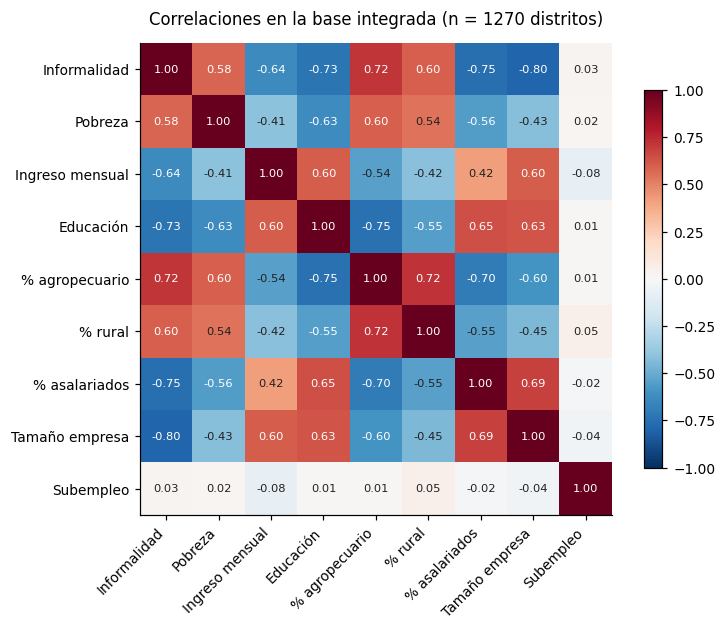

Informalidad ↔ pobreza:   r = 0.581
Educación    ↔ pobreza:   r = -0.627
Agropecuario ↔ informal.: r = 0.717
Subempleo    ↔ pobreza:   r = 0.019


In [ ]:
VARS_EDA = ["tasa_informalidad_pct", "pobreza_pct", "ingreso_mensual_soles",
            "nivel_educativo_promedio", "pct_agropecuario", "pct_rural",
            "pct_asalariados", "tamano_empresa_promedio", "tasa_subempleo_horas_pct"]
ETIQUETAS = ["Informalidad", "Pobreza", "Ingreso mensual", "Educación",
             "% agropecuario", "% rural", "% asalariados", "Tamaño empresa", "Subempleo"]

corr = base[VARS_EDA].corr()
corr.round(3).to_csv(CARPETA_OUT / "matriz_correlaciones_hito2.csv", encoding="utf-8-sig")

fig, ax = plt.subplots(figsize=(7.2, 5.8))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(VARS_EDA)), ETIQUETAS, rotation=45, ha="right")
ax.set_yticks(range(len(VARS_EDA)), ETIQUETAS)
for i in range(len(VARS_EDA)):
    for j in range(len(VARS_EDA)):
        v = corr.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(v) > .55 else "#222")
ax.set_title("Correlaciones en la base integrada (n = %d distritos)" % len(base), pad=12)
ax.grid(False); fig.colorbar(im, shrink=.8); fig.tight_layout()
fig.savefig(CARPETA_FIG / "01_correlaciones.png", dpi=160, bbox_inches="tight"); plt.show()

print(f"Informalidad ↔ pobreza:   r = {corr.loc['tasa_informalidad_pct','pobreza_pct']:.3f}")
print(f"Educación    ↔ pobreza:   r = {corr.loc['nivel_educativo_promedio','pobreza_pct']:.3f}")
print(f"Agropecuario ↔ informal.: r = {corr.loc['pct_agropecuario','tasa_informalidad_pct']:.3f}")
print(f"Subempleo    ↔ pobreza:   r = {corr.loc['tasa_subempleo_horas_pct','pobreza_pct']:.3f}")

**Hallazgo 6.1 — el resultado del Hito 1 se invierte.** Con la informalidad correctamente construida,
la correlación distrital entre informalidad y pobreza es **positiva y moderada (r ≈ 0.58)**, no nula.
Lo que el Hito 1 leyó como "dos fenómenos independientes" era el efecto de haber promediado un código
de informante. Los correlatos más fuertes de la informalidad, sin embargo, no son de pobreza sino
**estructurales**: tamaño de la empresa (r ≈ −0.80), proporción de asalariados (r ≈ −0.75), nivel
educativo (r ≈ −0.73) y peso del empleo agropecuario (r ≈ +0.72). La informalidad se parece más a un
indicador de estructura productiva que de ingreso.

**El subempleo por horas no se asocia con nada** (|r| < 0.11 con todas las demás variables). Se
conserva en la matriz porque mide una dimensión distinta del problema laboral, pero se advierte que no
aporta poder discriminante para la segmentación.

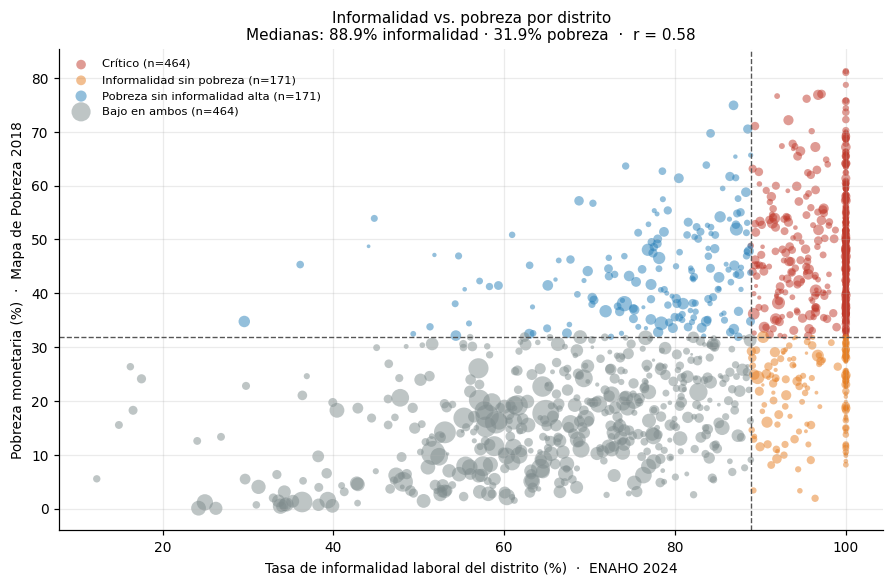

,distritos,poblacion,informalidad,pobreza,ingreso
cuadrante,,,,,
Bajo en ambos,464,24945892,66.1,16.2,1703.3
Crítico,464,3287806,97.8,48.2,923.0
Informalidad sin pobreza,171,1025613,96.6,22.5,1013.8
Pobreza sin informalidad alta,171,2065163,77.2,44.2,1468.5


In [ ]:
# --- 6.2 Dispersión informalidad vs. pobreza, con cuadrantes en las medianas ---
corte_inf = base["tasa_informalidad_pct"].median()
corte_pob = base["pobreza_pct"].median()

base["cuadrante"] = np.select(
    [(base.tasa_informalidad_pct >= corte_inf) & (base.pobreza_pct >= corte_pob),
     (base.tasa_informalidad_pct >= corte_inf) & (base.pobreza_pct <  corte_pob),
     (base.tasa_informalidad_pct <  corte_inf) & (base.pobreza_pct >= corte_pob)],
    ["Crítico", "Informalidad sin pobreza", "Pobreza sin informalidad alta"], "Bajo en ambos")

COLORES = {"Crítico": "#C0392B", "Informalidad sin pobreza": "#E67E22",
           "Pobreza sin informalidad alta": "#2980B9", "Bajo en ambos": "#7F8C8D"}

fig, ax = plt.subplots(figsize=(8.2, 5.4))
for cuad, col in COLORES.items():
    s = base[base.cuadrante == cuad]
    ax.scatter(s.tasa_informalidad_pct, s.pobreza_pct, s=np.sqrt(s.POBLACION_2020.clip(1)) / 3.5,
               c=col, alpha=.5, edgecolors="none", label=f"{cuad} (n={len(s)})")
ax.axvline(corte_inf, ls="--", c="#555", lw=.9); ax.axhline(corte_pob, ls="--", c="#555", lw=.9)
ax.set_xlabel("Tasa de informalidad laboral del distrito (%)  ·  ENAHO 2024")
ax.set_ylabel("Pobreza monetaria (%)  ·  Mapa de Pobreza 2018")
ax.set_title("Informalidad vs. pobreza por distrito\n"
             f"Medianas: {corte_inf:.1f}% informalidad · {corte_pob:.1f}% pobreza  ·  "
             f"r = {base.tasa_informalidad_pct.corr(base.pobreza_pct):.2f}", fontsize=10)
ax.legend(fontsize=7.5, loc="upper left", frameon=False); fig.tight_layout()
fig.savefig(CARPETA_FIG / "02_cuadrantes.png", dpi=160, bbox_inches="tight"); plt.show()

display(base.groupby("cuadrante").agg(
    distritos=("UBIGEO", "count"), poblacion=("POBLACION_2020", "sum"),
    informalidad=("tasa_informalidad_pct", "mean"), pobreza=("pobreza_pct", "mean"),
    ingreso=("ingreso_mensual_soles", "mean")).round(1))

,distritos,pobreza,informalidad,ingreso_mensual,educacion,pct_agro
tramo_pobreza,,,,,,
Q1 menos pobre,319,10.5,67.4,1705.2,6.5,24.3
Q2,316,25.4,81.2,1348.6,5.7,47.3
Q3,317,39.0,90.3,1162.8,5.0,63.7
Q4 más pobre,318,55.2,94.2,998.7,4.7,71.9


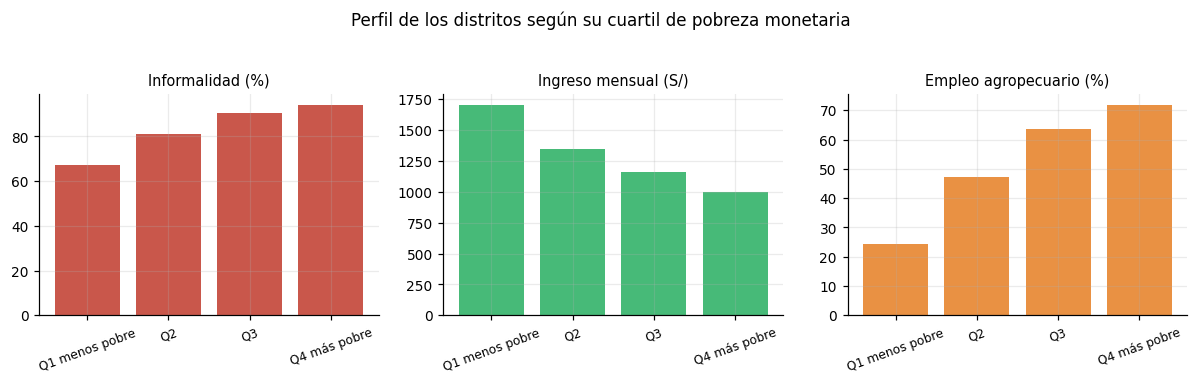

In [ ]:
# --- 6.3 ¿El cruce es correcto? Gradiente por tramo de pobreza ---
base["tramo_pobreza"] = pd.qcut(base["pobreza_pct"], 4,
                                labels=["Q1 menos pobre", "Q2", "Q3", "Q4 más pobre"])
perfil = base.groupby("tramo_pobreza", observed=True).agg(
    distritos=("UBIGEO", "count"),
    pobreza=("pobreza_pct", "mean"),
    informalidad=("tasa_informalidad_pct", "mean"),
    ingreso_mensual=("ingreso_mensual_soles", "mean"),
    educacion=("nivel_educativo_promedio", "mean"),
    pct_agro=("pct_agropecuario", "mean")).round(1)
display(perfil)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3))
for ax, (col, tit, color) in zip(axes, [
        ("informalidad", "Informalidad (%)", "#C0392B"),
        ("ingreso_mensual", "Ingreso mensual (S/)", "#27AE60"),
        ("pct_agro", "Empleo agropecuario (%)", "#E67E22")]):
    ax.bar(perfil.index.astype(str), perfil[col], color=color, alpha=.85)
    ax.set_title(tit, fontsize=9.5); ax.tick_params(axis="x", rotation=20, labelsize=8)
fig.suptitle("Perfil de los distritos según su cuartil de pobreza monetaria", y=1.04, fontsize=11)
fig.tight_layout(); fig.savefig(CARPETA_FIG / "03_gradiente.png", dpi=160, bbox_inches="tight"); plt.show()

**Hallazgo 6.2 — el cruce está bien hecho.** Las cuatro variables se ordenan de forma monótona a lo
largo de los cuartiles de pobreza: del cuartil menos pobre al más pobre la informalidad sube de 67 %
a 94 %, el ingreso mensual cae de S/ 1 684 a S/ 998, la educación baja y el empleo agropecuario pasa
de 24 % a 72 %. Si el `merge` por UBIGEO estuviera mal hecho, ninguna de estas gradientes aparecería.
Es el control metodológico que respalda todo lo demás.

**Hallazgo 6.3 — el cuadrante crítico tiene geografía.** Los 464 distritos que combinan informalidad
y pobreza por encima de la mediana concentran unos **3.3 millones de habitantes** y se ubican
prácticamente todos en Sierra (361) y Selva (86); **ninguno** está en Lima Metropolitana. Esto acota
qué instrumentos de formalización tienen sentido: en territorios donde el empleo predominante es
agropecuario y por cuenta propia, la fiscalización laboral a empresas no tiene sobre qué actuar.

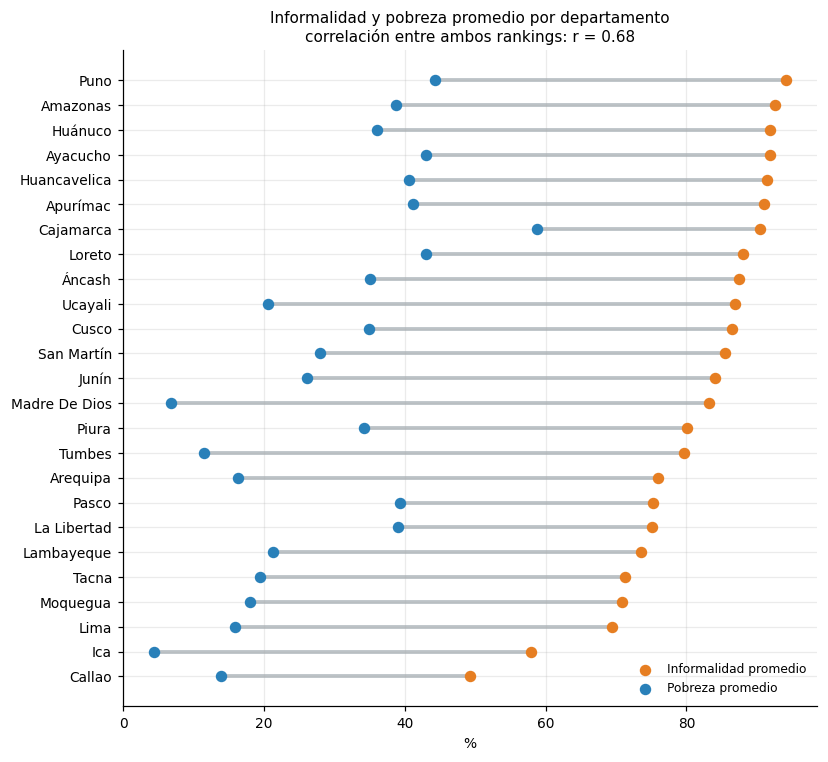

,informalidad,pobreza,distritos
DEPARTAMENTO,,,
Puno,94.1,44.3,71
Amazonas,92.6,38.7,53
Huánuco,91.9,36.1,60
Ayacucho,91.9,43.0,69
Huancavelica,91.5,40.6,64
Apurímac,91.0,41.1,59
Cajamarca,90.4,58.7,78
Loreto,88.1,43.0,44


In [ ]:
# --- 6.4 ¿Los dos diagnósticos coinciden a nivel departamental? ---
dep = (base.groupby("DEPARTAMENTO")
       .agg(informalidad=("tasa_informalidad_pct", "mean"),
            pobreza=("pobreza_pct", "mean"),
            distritos=("UBIGEO", "count")).round(1)
       .sort_values("informalidad"))

fig, ax = plt.subplots(figsize=(7.6, 7))
ax.hlines(dep.index, dep.informalidad, dep.pobreza, color="#BDC3C7", lw=2.5, zorder=1)
ax.scatter(dep.informalidad, dep.index, color="#E67E22", s=42, zorder=2, label="Informalidad promedio")
ax.scatter(dep.pobreza, dep.index, color="#2980B9", s=42, zorder=2, label="Pobreza promedio")
ax.set_xlabel("%")
ax.set_title(f"Informalidad y pobreza promedio por departamento\n"
             f"correlación entre ambos rankings: r = {dep.informalidad.corr(dep.pobreza):.2f}",
             fontsize=10)
ax.legend(fontsize=8, frameon=False, loc="lower right"); fig.tight_layout()
fig.savefig(CARPETA_FIG / "04_departamentos.png", dpi=160, bbox_inches="tight"); plt.show()
display(dep.sort_values("informalidad", ascending=False).head(8))

**Hallazgo 6.4 — los rankings coinciden, pero no se superponen.** La correlación entre el promedio
departamental de informalidad y el de pobreza es **positiva (r ≈ 0.68)**, lo contrario de lo que
reportó el Hito 1. Aun así, la brecha entre ambos indicadores sigue siendo informativa: Puno,
Amazonas y Huánuco encabezan la informalidad, mientras que Cajamarca, Loreto y Apurímac encabezan la
pobreza. El solapamiento es de dos departamentos (Puno y Ayacucho), de modo que **focalizar solo con
el mapa de pobreza seguiría dejando fuera territorios con informalidad muy alta** — el argumento
original del proyecto sigue en pie, ahora por la razón correcta: no porque los fenómenos sean
independientes, sino porque su intensidad relativa cambia según la estructura productiva del
territorio.

*Prudencia:* son promedios simples de distritos, no ponderados por población, y 105 de los 1 270
distritos tienen menos de 10 encuestados.

## 7. Transformación de variables

Solo se aplican transformaciones que el análisis posterior necesita; cada una se justifica.

| Tipo | Variable creada | Por qué |
|---|---|---|
| Derivada | `pobreza_pct`, `amplitud_ic` | El anexo no publica la tasa, sino el ranking y el IC |
| Derivada | `ingreso_mensual_soles` | `I524A1` viene en soles anuales |
| Derivada | `indice_vulnerabilidad` | Resume en una escala 0-100 las cuatro dimensiones del problema |
| Tratamiento de atípicos | `ingreso_mensual_w` | Winsorización al 1 % / 99 %: hay distritos con ingresos extremos sobre muestras chicas |
| Escala | `log_ingreso_mensual` | El ingreso es asimétrico a la derecha; el log lo hace comparable |
| Discretización | `tramo_pobreza`, `tramo_informalidad` | Permite comparar grupos de igual tamaño |
| Codificación | `es_predominante_rural`, `reg_*` | Variables categóricas utilizables por algoritmos numéricos |
| Escalamiento | sufijo `_z` | k-means y PCA requieren variables en la misma escala |

Winsorización del ingreso mensual en [S/ 131 ; S/ 3,702] · 26 distritos recortados


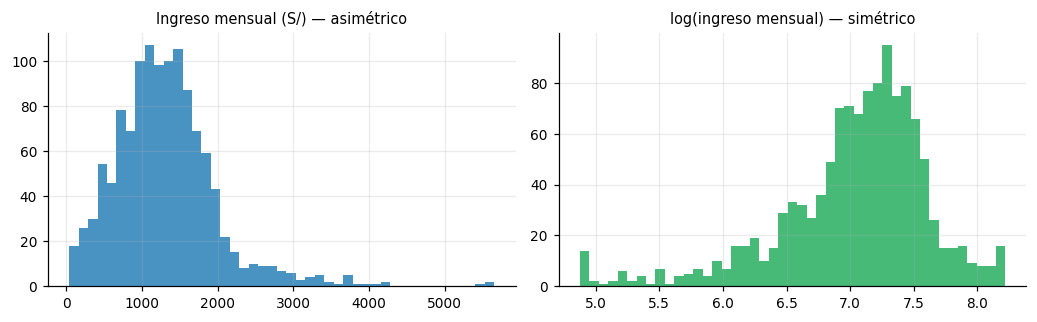

In [ ]:
# --- 7.1 Atípicos y escala del ingreso ---
lim_inf, lim_sup = base["ingreso_mensual_soles"].quantile([0.01, 0.99])
base["ingreso_mensual_w"] = base["ingreso_mensual_soles"].clip(lim_inf, lim_sup)
base["log_ingreso_mensual"] = np.log(base["ingreso_mensual_w"])
print(f"Winsorización del ingreso mensual en [S/ {lim_inf:,.0f} ; S/ {lim_sup:,.0f}] "
      f"· {int((base.ingreso_mensual_soles < lim_inf).sum() + (base.ingreso_mensual_soles > lim_sup).sum())} "
      f"distritos recortados")

fig, axes = plt.subplots(1, 2, figsize=(9.5, 3))
axes[0].hist(base.ingreso_mensual_soles.dropna(), bins=45, color="#2980B9", alpha=.85)
axes[0].set_title("Ingreso mensual (S/) — asimétrico", fontsize=9.5)
axes[1].hist(base.log_ingreso_mensual.dropna(), bins=45, color="#27AE60", alpha=.85)
axes[1].set_title("log(ingreso mensual) — simétrico", fontsize=9.5)
fig.tight_layout(); fig.savefig(CARPETA_FIG / "05_log_ingreso.png", dpi=160, bbox_inches="tight"); plt.show()

In [ ]:
# --- 7.2 Discretización y codificación ---
# Más del 30% de los distritos tiene 100% de informalidad, así que los cortes por valor no son
# únicos: se discretiza sobre el RANGO para obtener cuatro grupos del mismo tamaño.
print(f"Distritos con informalidad = 100%: {(base.tasa_informalidad_pct >= 99.99).mean():.1%}")
base["tramo_informalidad"] = pd.qcut(base["tasa_informalidad_pct"].rank(method="first"), 4,
                                     labels=["Q1 menos informal", "Q2", "Q3", "Q4 más informal"])

# Codificación binaria y one-hot (region_natural no es ordinal → dummies, no códigos 1..4)
base["muestra_suficiente"]     = base["n_muestra"] >= 10
base["es_predominante_rural"]  = (base["pct_rural"] >= 50).astype(int)
dummies = pd.get_dummies(base["region_natural"], prefix="reg").astype(int)
base = pd.concat([base, dummies], axis=1)

print("Variables indicadoras creadas:", list(dummies.columns))
display(pd.crosstab(base.tramo_informalidad, base.tramo_pobreza))

Distritos con informalidad = 100%: 30.1%
Variables indicadoras creadas: ['reg_Costa', 'reg_Lima Metropolitana', 'reg_Selva', 'reg_Sierra']


tramo_pobreza,Q1 menos pobre,Q2,Q3,Q4 más pobre
tramo_informalidad,,,,
Q1 menos informal,189,89,30,10
Q2,83,103,76,55
Q3,27,67,114,109
Q4 más informal,20,57,97,144


In [ ]:
# --- 7.3 Índice compuesto de vulnerabilidad (0-100) ---
# Promedia la posición percentil del distrito en las cuatro dimensiones del problema.
# Se usa el percentil y no el valor bruto para que ninguna variable domine por su escala.
base["indice_vulnerabilidad"] = ((
      base["tasa_informalidad_pct"].rank(pct=True)
    + base["pobreza_pct"].rank(pct=True)
    + base["tasa_subempleo_horas_pct"].rank(pct=True)
    + (1 - base["log_ingreso_mensual"].rank(pct=True))
) / 4 * 100).round(1)

top = (base[base.muestra_suficiente]
       .nlargest(12, "indice_vulnerabilidad")
       [["DISTRITO", "PROVINCIA", "DEPARTAMENTO", "n_muestra", "tasa_informalidad_pct",
         "pobreza_pct", "ingreso_mensual_w", "indice_vulnerabilidad"]].round(1))
print("12 distritos más vulnerables (solo con muestra ≥ 10 encuestados):")
display(top)

12 distritos más vulnerables (solo con muestra ≥ 10 encuestados):


,DISTRITO,PROVINCIA,DEPARTAMENTO,n_muestra,tasa_informalidad_pct,pobreza_pct,ingreso_mensual_w,indice_vulnerabilidad
349,Anguia,Chota,Cajamarca,14,100.0,78.7,350.6,93.3
356,Querocoto,Chota,Cajamarca,10,100.0,55.1,297.5,92.7
144,Kishuara,Andahuaylas,Apurímac,14,100.0,50.2,215.7,91.3
558,Yacus,Huánuco,Huánuco,14,100.0,49.9,131.1,91.2
566,Marías,Dos De Mayo,Huánuco,25,100.0,54.2,431.3,91.0
386,San José De Lourdes,San Ignacio,Cajamarca,11,100.0,48.3,151.8,90.6
74,San Nicolás,Carlos F. Fitzcarrald,Áncash,27,100.0,53.2,279.8,90.4
175,Chincheros,Chincheros,Apurímac,15,100.0,47.8,189.3,90.2
362,Tantarica,Contumazá,Cajamarca,21,100.0,51.4,496.8,90.1
368,Querocotillo,Cutervo,Cajamarca,23,100.0,69.2,301.4,89.8


In [ ]:
# --- 7.4 Escalamiento (z-score) ---
# Necesario para el clustering del Hito 3: sin estandarizar, el ingreso (miles) aplastaría
# a las tasas (0-100) en cualquier cálculo de distancia.
VARS_MODELO = ["tasa_informalidad_pct", "tasa_subempleo_horas_pct", "log_ingreso_mensual",
               "horas_promedio_semana", "nivel_educativo_promedio", "tamano_empresa_promedio",
               "pct_rural", "pct_agropecuario", "pct_asalariados", "pct_mujeres",
               "edad_promedio", "pobreza_pct"]

faltantes_modelo = base[VARS_MODELO].isna().sum()
print("Faltantes antes de escalar:")
display(faltantes_modelo[faltantes_modelo > 0].to_frame("faltantes"))
print("Se imputan por la MEDIANA de la variable (son distritos sin ingreso declarado, "
      "todos de muestra pequeña); la imputación queda marcada en `ingreso_imputado`.")

base["ingreso_imputado"] = base["ingreso_mensual_soles"].isna().astype(int)
X = base[VARS_MODELO].fillna(base[VARS_MODELO].median())
base[[c + "_z" for c in VARS_MODELO]] = StandardScaler().fit_transform(X)

chequeo = base[[c + "_z" for c in VARS_MODELO]].agg(["mean", "std"]).T.round(3)
chequeo.columns = ["media (≈0)", "desv. estándar (≈1)"]
display(chequeo)

Faltantes antes de escalar:


,faltantes
log_ingreso_mensual,67


Se imputan por la MEDIANA de la variable (son distritos sin ingreso declarado, todos de muestra pequeña); la imputación queda marcada en `ingreso_imputado`.


,media (≈0),desv. estándar (≈1)
tasa_informalidad_pct_z,-0.0,1.0
tasa_subempleo_horas_pct_z,-0.0,1.0
log_ingreso_mensual_z,0.0,1.0
horas_promedio_semana_z,0.0,1.0
nivel_educativo_promedio_z,0.0,1.0
tamano_empresa_promedio_z,0.0,1.0
pct_rural_z,0.0,1.0
pct_agropecuario_z,0.0,1.0
pct_asalariados_z,0.0,1.0
pct_mujeres_z,-0.0,1.0


## 8. Matriz analítica

**Qué representa cada fila:** un distrito del Perú con muestra en la ENAHO 2024 *y* estimación de
pobreza en el Mapa de Pobreza Distrital 2018, identificado por su UBIGEO.

**Qué se excluye y por qué:**

| Excluido | Motivo |
|---|---|
| `CODINFOR` | Es el código del informante del hogar; no aporta información analítica (sección 2.2) |
| `D524A1`, `P558T` | Redundante con `I524A1` la primera; monto de pensión y no afiliación la segunda |
| `AÑO`, `MES` | Constantes en todo el archivo |
| `CONGLOME`, `VIVIENDA`, `HOGAR`, `CODPERSO` | Identificadores de persona: desaparecen al agregar a distrito |
| 603 distritos sin muestra ENAHO | No tienen ninguna variable laboral; se documentan en 5.3, no se imputan |
| `RANKING_POBREZA` | Se conserva **solo como referencia**, fuera del bloque escalado: es un orden, no una magnitud |
| `tasa_subempleo_horas_pct` | **Se conserva pero se marca**: no correlaciona con ninguna otra variable (6.1) |

In [ ]:
IDENTIFICACION = ["UBIGEO", "DEPARTAMENTO", "PROVINCIA", "DISTRITO", "region_natural"]
CONTEXTO       = ["n_muestra", "muestra_suficiente", "poblacion_expandida", "POBLACION_2020",
                  "amplitud_ic", "GRUPOS_ROBUSTOS", "RANKING_POBREZA", "ingreso_imputado"]
ANALITICAS     = ["tasa_informalidad_pct", "tasa_subempleo_horas_pct", "pct_asalariados",
                  "pct_agropecuario", "pct_rural", "pct_mujeres", "ingreso_mensual_w",
                  "log_ingreso_mensual", "horas_promedio_semana", "edad_promedio",
                  "nivel_educativo_promedio", "tamano_empresa_promedio", "pobreza_pct"]
DERIVADAS      = ["es_predominante_rural", "tramo_pobreza", "tramo_informalidad", "cuadrante",
                  "indice_vulnerabilidad"] + list(dummies.columns)
ESCALADAS      = [c + "_z" for c in VARS_MODELO]

matriz = base[IDENTIFICACION + CONTEXTO + ANALITICAS + DERIVADAS + ESCALADAS].copy()

print(f"MATRIZ ANALÍTICA · {matriz.shape[0]:,} distritos × {matriz.shape[1]} variables")
print(f"  identificación {len(IDENTIFICACION)} | contexto {len(CONTEXTO)} | "
      f"analíticas {len(ANALITICAS)} | derivadas {len(DERIVADAS)} | escaladas {len(ESCALADAS)}")
display(matriz.head())

MATRIZ ANALÍTICA · 1,270 distritos × 47 variables
  identificación 5 | contexto 8 | analíticas 13 | derivadas 9 | escaladas 12


,UBIGEO,DEPARTAMENTO,PROVINCIA,DISTRITO,region_natural,n_muestra,muestra_suficiente,poblacion_expandida,POBLACION_2020,amplitud_ic,GRUPOS_ROBUSTOS,RANKING_POBREZA,ingreso_imputado,tasa_informalidad_pct,tasa_subempleo_horas_pct,pct_asalariados,pct_agropecuario,pct_rural,pct_mujeres,ingreso_mensual_w,log_ingreso_mensual,horas_promedio_semana,edad_promedio,nivel_educativo_promedio,tamano_empresa_promedio,pobreza_pct,es_predominante_rural,tramo_pobreza,tramo_informalidad,cuadrante,indice_vulnerabilidad,reg_Costa,reg_Lima Metropolitana,reg_Selva,reg_Sierra,tasa_informalidad_pct_z,tasa_subempleo_horas_pct_z,log_ingreso_mensual_z,horas_promedio_semana_z,nivel_educativo_promedio_z,tamano_empresa_promedio_z,pct_rural_z,pct_agropecuario_z,pct_asalariados_z,pct_mujeres_z,edad_promedio_z,pobreza_pct_z
0,010101,Amazonas,Chachapoyas,Chachapoyas,Sierra,245,True,33314.839689,39051,6.521794,19,1747,0,64.323374,6.527779,47.948621,16.202222,4.386420,48.499579,1841.749433,7.518471,42.487500,42.468541,6.791082,2.039569,9.034625,0,Q1 menos pobre,Q1 menos informal,Bajo en ambos,24.8,0,0,0,1,-1.056907,-0.128370,0.839082,0.785449,1.213395,1.102714,-1.230219,-1.173474,0.595879,0.641567,0.152984,-1.349985
1,010104,Amazonas,Chachapoyas,Cheto,Sierra,15,True,1215.234537,702,22.445156,10,754,0,100.000000,29.749593,39.220792,82.807176,100.000000,34.443838,637.914788,6.458205,36.577750,40.920576,5.192752,1.000000,39.169782,1,Q3,Q3,Crítico,82.7,0,0,0,1,0.936214,2.255912,-1.008465,0.010079,-0.239847,-0.980350,0.932481,1.023544,0.173151,-0.623840,-0.143966,0.382035
2,010106,Amazonas,Chachapoyas,Chuquibamba,Sierra,15,True,1153.544394,1933,16.796071,7,315,1,100.000000,0.000000,0.000000,100.000000,100.000000,36.488974,NaN,NaN,43.650196,39.617751,4.716479,1.000000,51.607832,1,Q4 más pobre,Q3,Crítico,NaN,0,0,0,1,0.936214,-0.798605,0.171807,0.937997,-0.672887,-0.980350,0.932481,1.590663,-1.726485,-0.439721,-0.393890,1.096913
3,010109,Amazonas,Chachapoyas,La Jalca,Sierra,28,True,1979.041037,3966,16.850888,8,426,0,100.000000,0.000000,8.981649,83.669693,100.000000,40.310847,327.694374,5.792081,43.802186,41.021239,4.201950,1.000000,47.947723,1,Q4 más pobre,Q3,Crítico,69.3,0,0,0,1,0.936214,-0.798605,-2.169206,0.957938,-1.140709,-0.980350,0.932481,1.051995,-1.291464,-0.095646,-0.124655,0.886548
4,010110,Amazonas,Chachapoyas,Leimebamba,Sierra,33,True,4567.559685,3815,13.004086,14,1230,0,80.339598,0.990809,56.537302,41.574133,30.773282,40.932882,2073.891183,7.637182,36.910037,42.309276,6.215732,2.122128,25.741684,0,Q2,Q2,Bajo en ambos,29.9,0,0,0,1,-0.162140,-0.696875,1.045939,0.053676,0.690273,1.268145,-0.633370,-0.336561,1.011866,-0.039646,0.122432,-0.389745


In [ ]:
# --- Diccionario de la matriz analítica ---
BLOQUE = ({c: "Identificación" for c in IDENTIFICACION} | {c: "Contexto / control" for c in CONTEXTO}
          | {c: "Analítica (original)" for c in ANALITICAS} | {c: "Derivada / codificada" for c in DERIVADAS}
          | {c: "Escalada (z-score)" for c in ESCALADAS})
ORIGEN = {**{c: "Mapa de Pobreza 2018" for c in
             ["DEPARTAMENTO","PROVINCIA","DISTRITO","POBLACION_2020","amplitud_ic",
              "GRUPOS_ROBUSTOS","RANKING_POBREZA","pobreza_pct","pobreza_pct_z","tramo_pobreza"]},
          **{c: "Derivada de ambas" for c in ["cuadrante","indice_vulnerabilidad"]},
          "UBIGEO": "Ambas (clave)"}

diccionario = pd.DataFrame({
    "variable": matriz.columns,
    "bloque": [BLOQUE[c] for c in matriz.columns],
    "origen": [ORIGEN.get(c, "ENAHO 2024 (agregada)") for c in matriz.columns],
    "tipo": [str(matriz[c].dtype) for c in matriz.columns],
    "faltantes": [int(matriz[c].isna().sum()) for c in matriz.columns],
})
display(diccionario)

# --- Validación final antes de exportar ---
assert matriz["UBIGEO"].is_unique, "Hay UBIGEO repetidos"
assert matriz["UBIGEO"].str.fullmatch(r"\d{6}").all(), "Hay UBIGEO mal formados"
assert matriz[ESCALADAS].isna().sum().sum() == 0, "Quedaron faltantes en las variables escaladas"
print("Validación final superada: clave única, formato correcto, sin faltantes en el bloque escalado.")

matriz.to_csv(CARPETA_OUT / "matriz_analitica_distrital.csv", index=False, encoding="utf-8-sig")
diccionario.to_csv(CARPETA_OUT / "diccionario_matriz_analitica.csv", index=False, encoding="utf-8-sig")
base.to_csv(CARPETA_OUT / "base_integrada_hito2.csv", index=False, encoding="utf-8-sig")
print("\nArchivos exportados en 'output/':")
for f in sorted(CARPETA_OUT.glob("*.csv")):
    print(f"  · {f.name}  ({f.stat().st_size/1024:,.0f} KB)")

,variable,bloque,origen,tipo,faltantes
0,UBIGEO,Identificación,Ambas (clave),object,0
1,DEPARTAMENTO,Identificación,Mapa de Pobreza 2018,object,0
2,PROVINCIA,Identificación,Mapa de Pobreza 2018,object,0
3,DISTRITO,Identificación,Mapa de Pobreza 2018,object,0
4,region_natural,Identificación,ENAHO 2024 (agregada),object,0
5,n_muestra,Contexto / control,ENAHO 2024 (agregada),int64,0
6,muestra_suficiente,Contexto / control,ENAHO 2024 (agregada),bool,0
7,poblacion_expandida,Contexto / control,ENAHO 2024 (agregada),float64,0
8,POBLACION_2020,Contexto / control,Mapa de Pobreza 2018,int64,0
9,amplitud_ic,Contexto / control,Mapa de Pobreza 2018,float64,0


Validación final superada: clave única, formato correcto, sin faltantes en el bloque escalado.



Archivos exportados en 'output/':
  · base_distrital_ampliada_2024.csv  (288 KB)
  · base_integrada_hito2.csv  (790 KB)
  · diccionario_matriz_analitica.csv  (3 KB)
  · matriz_analitica_distrital.csv  (733 KB)
  · matriz_correlaciones.csv  (3 KB)
  · matriz_correlaciones_hito2.csv  (1 KB)
  · pobreza_informalidad_departamental_2024.csv  (285 KB)
  · tabla_decisiones_calidad.csv  (2 KB)


## 9. Próximo paso

Con la matriz analítica lista, el Hito 3 aplicará **segmentación no supervisada (k-means)** sobre el
bloque de variables escaladas, para agrupar distritos por *perfil* de informalidad y no solo por su
nivel. La hipótesis a validar es que existen al menos tres tipos de territorio informal —agropecuario
de subsistencia, urbano por cuenta propia, y asalariado sin protección— y que cada uno requiere un
instrumento de política distinto.

Antes de eso quedan dos cosas por validar: **(a)** el efecto del desfase 2018–2024 entre fuentes,
contrastando la pobreza departamental 2024 publicada por el INEI con la del mapa distrital; y
**(b)** la estabilidad de los grupos al excluir los 105 distritos con menos de 10 encuestados.

---

### Reproducir este cuaderno

```bash
pip install -r requirements.txt
```

Colocar en `DB/` los dos archivos originales del INEI (`2024Empleo e Ingresos.csv` y
`Anexo Estadístico.xlsx`, ver README) y ejecutar el cuaderno de arriba abajo. Todas las salidas se
escriben en `output/`.